# MobileNet特征与Pass/Fail、Likert评分的关系

使用当前Pass/Fail视频的现有before_1–3、after_1–3图片，保持原MobileNetV3-Small提取方法：每帧576维，事件特征为前后平均特征的绝对差（576维）加9组前后余弦相似度中位数（1维），共577维。

距离定义为 **1 − 9组余弦相似度的中位数**，与现有事件特征最后一维对应。图片为现有完整截图，场景背景、光照与目标物体都可能影响特征。

全部图形均为探索性描述：PCA在展示样本上拟合，不能作为独立测试性能；不调整模型或阈值。Likert评分来自连续帧初评，相关不代表因果。

In [1]:
from pathlib import Path
import hashlib, io
import numpy as np
import pandas as pd
import torch
from PIL import Image as PILImage
from torchvision.models import mobilenet_v3_small, MobileNet_V3_Small_Weights
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from scipy.stats import spearmanr
ROOT=next((p for p in [Path.cwd(),*Path.cwd().parents] if (p/'data/labeled_data/0_PASS/0_PASS.xlsx').exists()),Path.home()/'Desktop/oae')
OUT=ROOT/'code/feature_visualization_results';OUT.mkdir(exist_ok=True)
plt.rcParams['font.sans-serif']=['Arial Unicode MS','Heiti SC','DejaVu Sans']
plt.rcParams['axes.unicode_minus']=False
plt.rcParams['figure.dpi']=130
COLORS={'Pass':'#3274A1','Fail':'#DF7653'}
def show(fig,name):
    fig.tight_layout();fig.savefig(OUT/name,dpi=160,bbox_inches='tight')
    buffer=io.BytesIO();fig.savefig(buffer,format='png',bbox_inches='tight')
    display(Image(data=buffer.getvalue()));plt.close(fig)
parts=[]
for label,folder in [('Pass','0_PASS'),('Fail','1_FAIL')]:
    df=pd.read_excel(ROOT/'data/labeled_data'/folder/(folder+'.xlsx'))
    df=df[['ID','consistency','清晰度评分（1–5）','流畅度评分（1–5）']].copy()
    df['类别']=label;df['图片目录']=str(ROOT/'data/labeled_data'/folder/'img')
    parts.append(df)
metadata=pd.concat(parts,ignore_index=True).sort_values('ID').reset_index(drop=True)
assert metadata.ID.notna().all() and not metadata.ID.duplicated().any()
assert all(metadata.loc[metadata['类别']==label,'consistency'].eq(value).all() for label,value in [('Pass',0),('Fail',1)])
for col in ['清晰度评分（1–5）','流畅度评分（1–5）']:assert metadata[col].isin([1,2,3,4,5]).all()


In [2]:
# 缓存按图片内容及模型权重校验；修改截图后会重新提取。
weights_path=Path.home()/'.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth'
if not weights_path.exists():
    raise FileNotFoundError('请先运行原MobileNet Notebook下载预训练权重：'+str(weights_path))
paths=[];eligible=[];failures=[];digest=hashlib.sha256(weights_path.read_bytes())
for row in metadata.to_dict('records'):
    images=[Path(row['图片目录'])/row['ID']/f'{side}_{i}.png' for side in ['before','after'] for i in [1,2,3]]
    missing=[str(path) for path in images if not path.exists()]
    if missing:
        failures.append({'ID':row['ID'],'error':'缺少图片：'+'; '.join(missing)});continue
    digest.update(row['ID'].encode())
    for path in images:digest.update(hashlib.sha256(path.read_bytes()).digest())
    eligible.append(row['ID']);paths.append(images)
signature=digest.hexdigest();cache=OUT/'current_features.npz'
frames=None
if cache.exists():
    with np.load(cache,allow_pickle=False) as saved:
        if str(saved['signature'].item())==signature and saved['ids'].tolist()==eligible:
            frames=saved['frames'].copy()
if frames is None:
    torch.set_num_threads(4)
    model=mobilenet_v3_small(weights=None)
    model.load_state_dict(torch.load(weights_path,map_location='cpu',weights_only=True))
    model.eval();model.requires_grad_(False)
    preprocess=MobileNet_V3_Small_Weights.DEFAULT.transforms()
    extracted=[]
    for index,images in enumerate(paths):
        tensors=[]
        for path in images:
            with PILImage.open(path) as im:tensors.append(preprocess(im.convert('RGB')))
        with torch.inference_mode():
            f=model.avgpool(model.features(torch.stack(tensors))).flatten(1).numpy()
        assert f.shape==(6,576) and np.isfinite(f).all()
        extracted.append(f)
        if (index+1)%50==0:print(f'已提取{index+1}/{len(paths)}条',flush=True)
    frames=np.stack(extracted)
    np.savez_compressed(cache,ids=np.array(eligible),frames=frames,signature=np.array(signature))
data=metadata.set_index('ID').loc[eligible].reset_index()
print(f'请求{len(metadata)}条，成功{len(data)}条，缺图{len(failures)}条；特征形状：{frames.shape}')
if failures:display(pd.DataFrame(failures))
assert len(data)>0


已提取50/351条
已提取100/351条
已提取150/351条
已提取200/351条
已提取250/351条
已提取300/351条
已提取350/351条
请求351条，成功351条，缺图0条；特征形状：(351, 6, 576)


In [3]:
before,after=frames[:,:3],frames[:,3:]
before_norm=before/np.maximum(np.linalg.norm(before,axis=2,keepdims=True),1e-8)
after_norm=after/np.maximum(np.linalg.norm(after,axis=2,keepdims=True),1e-8)
similarities=np.einsum('nid,njd->nij',before_norm,after_norm).reshape(-1,9)
median_similarity=np.clip(np.median(similarities,axis=1),-1,1)
event_features=np.column_stack([np.abs(before.mean(axis=1)-after.mean(axis=1)),median_similarity])
assert event_features.shape==(len(data),577)
data['前后余弦距离']=1-median_similarity
print('事件特征形状：',event_features.shape)
display(data.groupby('类别')['前后余弦距离'].agg(['count','median','mean','min','max']))
data.drop(columns='图片目录').to_csv(OUT/'event_distances_and_scores.csv',index=False)


事件特征形状： (351, 577)


,count,median,mean,min,max
类别,,,,,
Fail,47,0.052603,0.074784,0.001227,0.364410
Pass,304,0.048501,0.077065,0.000903,0.458373


## 图1：Pass与Fail的前后特征距离
左侧每类直方图分别归一化为密度，右侧显示中位数与分布。距离越大表示前后特征差异越大；不等于外观一定不一致。

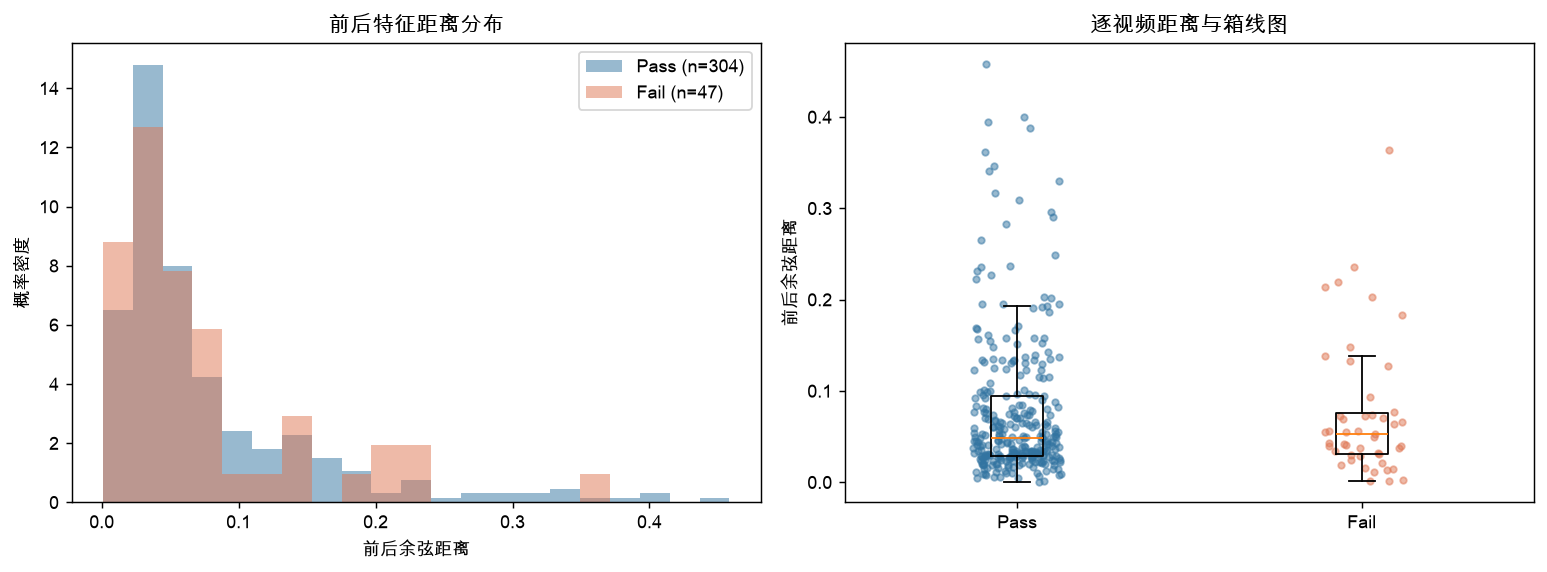

In [4]:
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
bins=np.linspace(data['前后余弦距离'].min(),data['前后余弦距离'].max()+1e-6,22)
for label,color in COLORS.items():
    values=data.loc[data['类别']==label,'前后余弦距离']
    axes[0].hist(values,bins=bins,density=True,alpha=.5,color=color,label=f'{label} (n={len(values)})')
axes[0].set(xlabel='前后余弦距离',ylabel='概率密度',title='前后特征距离分布');axes[0].legend()
values=[data.loc[data['类别']==label,'前后余弦距离'] for label in COLORS]
axes[1].boxplot(values,tick_labels=list(COLORS),showfliers=False)
rng=np.random.default_rng(42)
for i,(label,color) in enumerate(COLORS.items(),1):
    v=values[i-1];axes[1].scatter(i+rng.uniform(-.13,.13,len(v)),v,s=13,alpha=.5,color=color)
axes[1].set(ylabel='前后余弦距离',title='逐视频距离与箱线图')
show(fig,'01_cosine_distance_distribution.png')


## 图2：577维事件特征的PCA投影
先标准化每个特征维度，再投影至二维；坐标轴标注解释方差。两个面板使用相同坐标，右图突出数量较少的Fail。

前两个主成分合计解释方差：22.4%


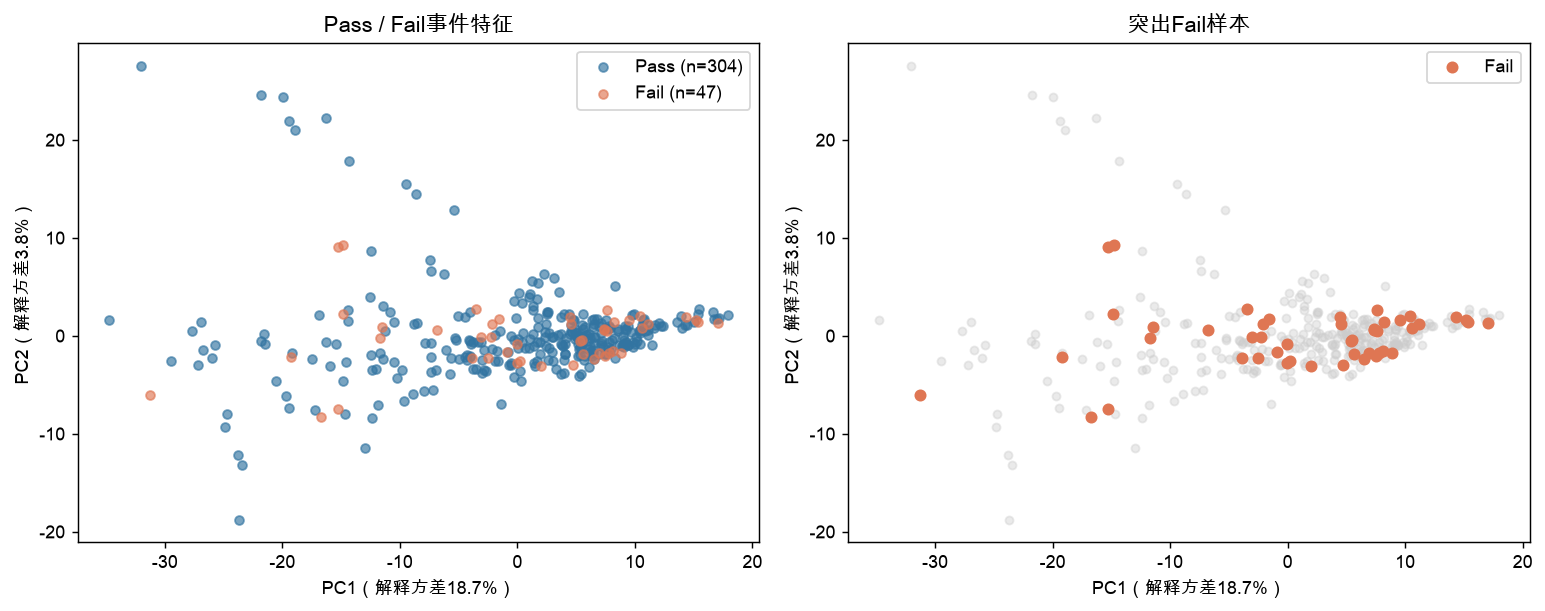

In [5]:
scaled=StandardScaler().fit_transform(event_features)
pca=PCA(n_components=2,svd_solver='full')
coordinates=pca.fit_transform(scaled)
data['PC1']=coordinates[:,0];data['PC2']=coordinates[:,1]
fig,axes=plt.subplots(1,2,figsize=(12,4.8))
for label,color in COLORS.items():
    part=data.loc[data['类别']==label]
    axes[0].scatter(part.PC1,part.PC2,s=24,alpha=.65,color=color,label=f'{label} (n={len(part)})')
axes[1].scatter(data.PC1,data.PC2,color='#cccccc',s=20,alpha=.4)
part=data.loc[data['类别']=='Fail'];axes[1].scatter(part.PC1,part.PC2,color=COLORS['Fail'],s=32,label='Fail')
for ax in axes:
    ax.set(xlabel=f'PC1（解释方差{pca.explained_variance_ratio_[0]:.1%}）',ylabel=f'PC2（解释方差{pca.explained_variance_ratio_[1]:.1%}）');ax.legend()
axes[0].set_title('Pass / Fail事件特征');axes[1].set_title('突出Fail样本')
show(fig,'02_event_feature_pca.png')
print(f'前两个主成分合计解释方差：{pca.explained_variance_ratio_.sum():.1%}')


## 图3：特征距离与Likert评分
横向轻微抖动仅用于显示重叠的点，原始评分仍为整数。相关系数按总体及Pass、Fail分别报告，避免只看混合样本关联。

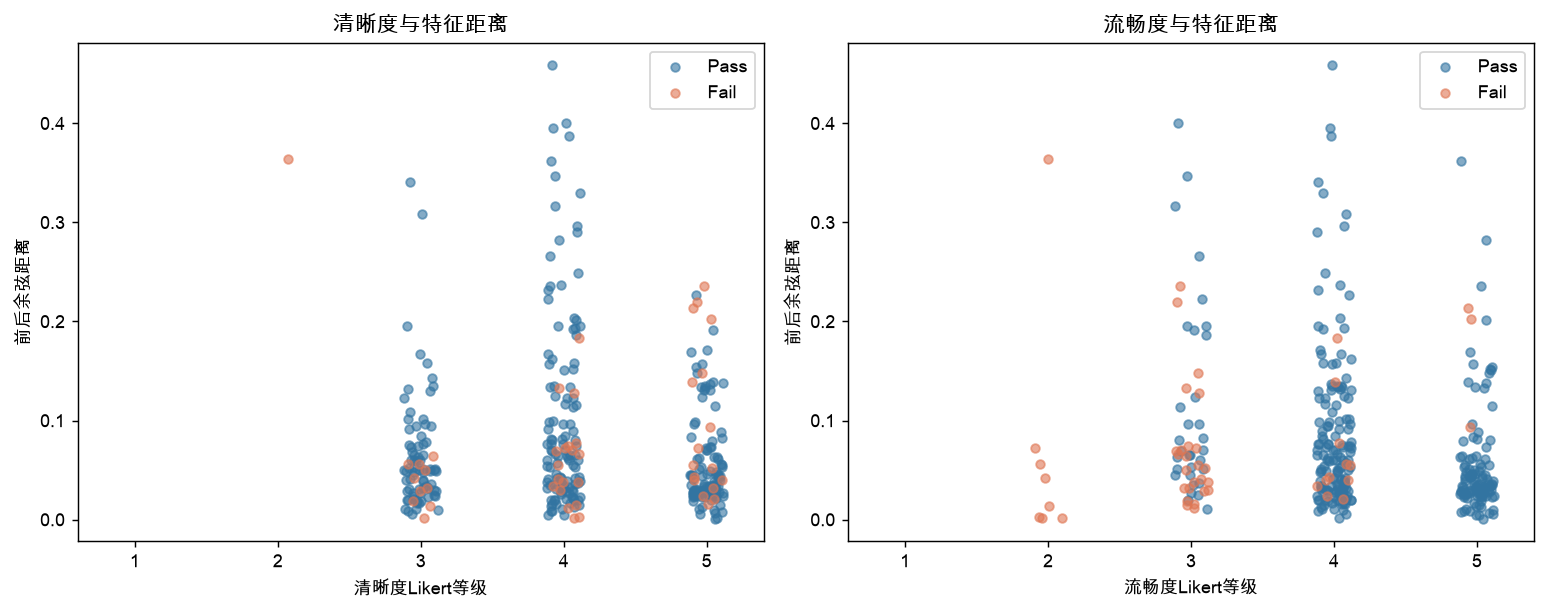

,评分维度,类别,样本数,Spearman相关系数
0,清晰度,总体,351,-0.057
1,清晰度,Pass,304,-0.099
2,清晰度,Fail,47,0.227
3,流畅度,总体,351,-0.189
4,流畅度,Pass,304,-0.281
5,流畅度,Fail,47,0.272


In [6]:
fig,axes=plt.subplots(1,2,figsize=(12,4.8));rng=np.random.default_rng(42);relations=[]
for ax,metric in zip(axes,['清晰度','流畅度']):
    col=metric+'评分（1–5）'
    for label,color in COLORS.items():
        part=data.loc[data['类别']==label]
        ax.scatter(part[col]+rng.uniform(-.12,.12,len(part)),part['前后余弦距离'],s=23,alpha=.6,color=color,label=label)
    ax.set(xlabel=metric+'Likert等级',ylabel='前后余弦距离',xticks=[1,2,3,4,5],xlim=(.6,5.4),title=metric+'与特征距离');ax.legend()
    for label in ['总体','Pass','Fail']:
        part=data if label=='总体' else data.loc[data['类别']==label]
        rho=spearmanr(part[col],part['前后余弦距离']).statistic if part[col].nunique()>1 else np.nan
        relations.append({'评分维度':metric,'类别':label,'样本数':len(part),'Spearman相关系数':rho})
show(fig,'03_distance_vs_likert.png')
relations=pd.DataFrame(relations)
display(relations.style.format({'Spearman相关系数':'{:.3f}'}))
relations.to_csv(OUT/'likert_distance_correlations.csv',index=False)
